# Predictions Test Analysis

Analysis of model predictions on the NIST23 test set, joining:
- `data/predicted/predictions_test.pkl` — model outputs and cosine similarity scores
- `data/proc/nist23/spec_df.pkl` — spectrum metadata
- `data/proc/nist23/mol_df.pkl` — molecule metadata
- `data/classyfire/nist23_mol_classyfire.pkl` — ClassyFire chemical taxonomy labels

In [1]:
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

DATA_ROOT = Path("../data")

## 1. Load Data

In [2]:
with open(DATA_ROOT / "predicted/predictions_test.pkl", "rb") as f:
    pred_df = pickle.load(f)

with open(DATA_ROOT / "proc/nist23/spec_df.pkl", "rb") as f:
    spec_df = pickle.load(f)

with open(DATA_ROOT / "proc/nist23/mol_df.pkl", "rb") as f:
    mol_df = pickle.load(f)
mol_df = mol_df.drop(columns=["mol"], errors="ignore")

with open(DATA_ROOT / "classyfire/nist23_mol_classyfire.pkl", "rb") as f:
    cf_df = pickle.load(f)

print(f"pred_df:  {pred_df.shape}")
print(f"spec_df:  {spec_df.shape}")
print(f"mol_df:   {mol_df.shape}")
print(f"cf_df:    {cf_df.shape}")

pred_df:  (85660, 10)
spec_df:  (1899597, 22)
mol_df:   (52787, 13)
cf_df:    (52787, 10)


In [3]:
pred_df.head(3)

,spec_id,mol_id,pred_mzs,pred_ints,pred_oos_prob,frag_formula_peak_idxs,frag_formula_peak_mzs,index_rebased,cos_sim_0.01,cos_hun
0,418,34523,"[220.0635986328125, 186.10256958007812, 222.07...","[1.2268697023391724, 4.8837103843688965, 999.9...",0.020965,"[30, 36, 38, 58, 407, 411]","[220.0635986328125, 186.10256958007812, 222.07...",True,0.999276,0.999276
1,419,34523,"[194.06053161621094, 173.09475708007812, 220.0...","[1.18855881690979, 4.235246658325195, 2.647926...",0.027789,"[1, 4, 30, 32, 36, 38, 40, 58, 147, 315, 407, ...","[194.06053161621094, 173.09475708007812, 220.0...",True,0.986549,0.986549
2,420,34523,"[194.06053161621094, 173.09475708007812, 174.1...","[1.0735852718353271, 13.810319900512695, 2.423...",0.031115,"[1, 4, 8, 28, 30, 32, 36, 38, 40, 58, 147, 315...","[194.06053161621094, 173.09475708007812, 174.1...",True,0.877749,0.877749


In [4]:
spec_df.head(3)

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,nce,prec_mz,peaks,ri,group_id,ace_extra_1,nce_extra_1,ace_extra_2,nce_extra_2,ce_type
0,0,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461655,N2,...,44.0,132.0768,"[(53.0135, 2.4), (55.018, 55.2), (55.0292, 4.2...",NaN,0,NaN,NaN,NaN,NaN,single
1,1,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461656,N2,...,54.0,132.0768,"[(53.0135, 5.6), (55.018, 82.6), (55.0293, 7.1...",NaN,0,NaN,NaN,NaN,NaN,single
2,2,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461657,N2,...,65.0,132.0768,"[(51.0231, 8.7), (53.0136, 12.1), (55.018, 107...",NaN,0,NaN,NaN,NaN,NaN,single


In [5]:
mol_df.head(3)

,smiles,mol_id,inchikey_s,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,*C1(C)C(OC2OC(CO)C(O)C(OC3OC(CO)C(O)C(O)C3O)C2...,0,,O=C(OC1CCCCO1)C12CCCCC1C1=CCC3C4CCC(OC5CC(OC6C...,C47H75*O19,,944.098,943.490255,67,74,0,True,0
1,BrC(Br)(Br)c1cnc2ccccc2n1,1,VCCOPRMZNNMFLI,c1ccc2nccnc2c1,C9H5Br3N2,"InChI=1S/C9H5Br3N2/c10-9(11,12)8-5-13-6-3-1-2-...",380.865,377.800284,14,15,0,True,0
2,BrC1=CCCN(Cc2ccccc2)C1,2,OFHMQSKRHZDSQE,C1=CCN(Cc2ccccc2)CC1,C12H14BrN,InChI=1S/C12H14BrN/c13-12-7-4-8-14(10-12)9-11-...,252.155,251.030962,14,15,0,True,0


## 2. Merge DataFrames

In [6]:
# Merge predictions with spectrum metadata
spec_meta_cols = [
    "spec_id", "mol_id", "prec_type", "inst_type", "frag_mode",
    "ion_mode", "dset", "ace", "nce", "ce_type",
]
df = pred_df.merge(spec_df[spec_meta_cols], on=["spec_id", "mol_id"], how="left")

# Merge with molecule metadata
mol_meta_cols = ["mol_id", "smiles", "formula", "mw", "exact_mw", "num_atoms", "num_bonds", "inchikey_s"]
df = df.merge(mol_df[mol_meta_cols], on="mol_id", how="left")

# Merge with ClassyFire labels
cf_meta_cols = ["mol_id", "superklass", "klass", "subklass", "direct_parent"]
df = df.merge(cf_df[cf_meta_cols], on="mol_id", how="left")

print(f"Merged df: {df.shape}")
df.head(3)

Merged df: (85660, 29)


,spec_id,mol_id,pred_mzs,pred_ints,pred_oos_prob,frag_formula_peak_idxs,frag_formula_peak_mzs,index_rebased,cos_sim_0.01,cos_hun,...,formula,mw,exact_mw,num_atoms,num_bonds,inchikey_s,superklass,klass,subklass,direct_parent
0,418,34523,"[220.0635986328125, 186.10256958007812, 222.07...","[1.2268697023391724, 4.8837103843688965, 999.9...",0.020965,"[30, 36, 38, 58, 407, 411]","[220.0635986328125, 186.10256958007812, 222.07...",True,0.999276,0.999276,...,C11H12ClN3,221.691,221.071975,15,17,GNXNQWVLLARLEP,organoheterocyclic compounds,benzimidazoles,benzimidazoles,benzimidazoles
1,419,34523,"[194.06053161621094, 173.09475708007812, 220.0...","[1.18855881690979, 4.235246658325195, 2.647926...",0.027789,"[1, 4, 30, 32, 36, 38, 40, 58, 147, 315, 407, ...","[194.06053161621094, 173.09475708007812, 220.0...",True,0.986549,0.986549,...,C11H12ClN3,221.691,221.071975,15,17,GNXNQWVLLARLEP,organoheterocyclic compounds,benzimidazoles,benzimidazoles,benzimidazoles
2,420,34523,"[194.06053161621094, 173.09475708007812, 174.1...","[1.0735852718353271, 13.810319900512695, 2.423...",0.031115,"[1, 4, 8, 28, 30, 32, 36, 38, 40, 58, 147, 315...","[194.06053161621094, 173.09475708007812, 174.1...",True,0.877749,0.877749,...,C11H12ClN3,221.691,221.071975,15,17,GNXNQWVLLARLEP,organoheterocyclic compounds,benzimidazoles,benzimidazoles,benzimidazoles


## 3. Overall Similarity Score Distribution

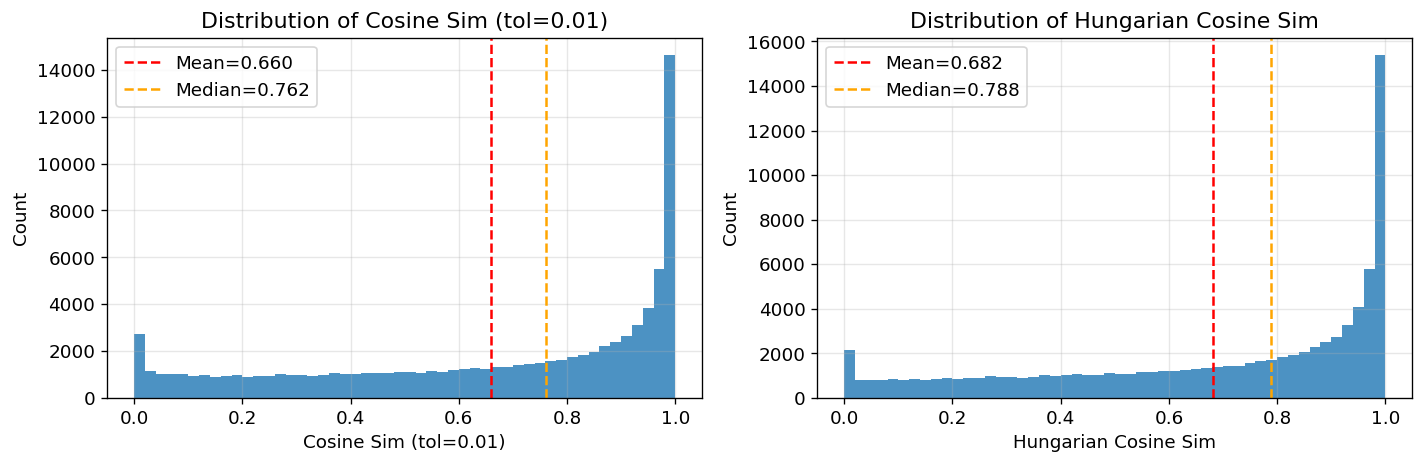

       cos_sim_0.01     cos_hun
count    85660.0000  85660.0000
mean         0.6595      0.6819
std          0.3203      0.3086
min          0.0000      0.0000
25%          0.4051      0.4506
50%          0.7620      0.7881
75%          0.9536      0.9589
max          1.0000      1.0000


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col, label in zip(
    axes,
    ["cos_sim_0.01", "cos_hun"],
    ["Cosine Sim (tol=0.01)", "Hungarian Cosine Sim"],
):
    ax.hist(df[col], bins=50, edgecolor="none", alpha=0.8)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label=f"Mean={df[col].mean():.3f}")
    ax.axvline(df[col].median(), color="orange", linestyle="--", label=f"Median={df[col].median():.3f}")
    ax.set_xlabel(label)
    ax.set_ylabel("Count")
    ax.set_title(f"Distribution of {label}")
    ax.legend()

plt.tight_layout()
plt.show()

print(df[["cos_sim_0.01", "cos_hun"]].describe().round(4))

## 4. Performance by Instrument Type

In [8]:
inst_stats = (
    df.groupby("inst_type")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
inst_stats

cos_sim_0.01                cos_hun               
                  mean  median  count    mean  median  count
inst_type                                                   
FT              0.6660  0.7687  80801  0.6914  0.7959  80801
IT              0.0233  0.0000     35  0.0008  0.0000     35
QTOF            0.5557  0.6147   4824  0.5268  0.5753   4824

/tmp/ipykernel_402002/3351175935.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=inst_order, patch_artist=True, showfliers=False,


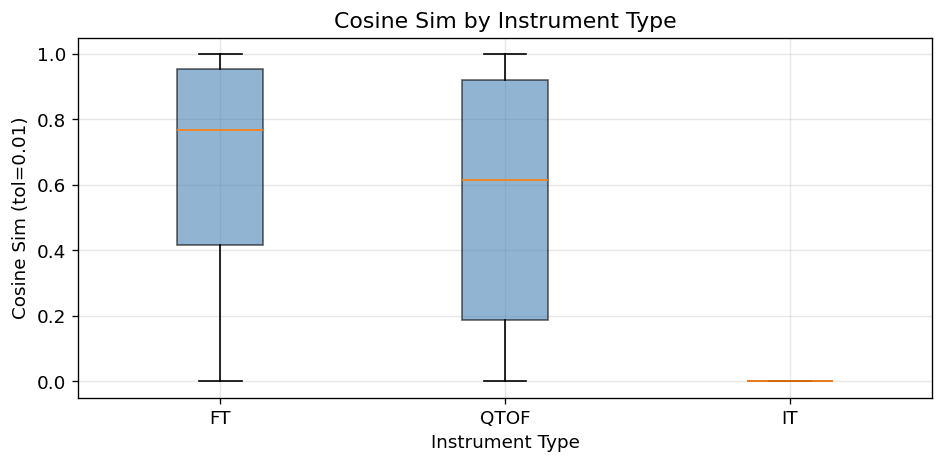

In [9]:
inst_order = df.groupby("inst_type")["cos_sim_0.01"].median().sort_values(ascending=False).index.tolist()
groups = [df.loc[df["inst_type"] == g, "cos_sim_0.01"].dropna().values for g in inst_order]

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(groups, labels=inst_order, patch_artist=True, showfliers=False,
           boxprops=dict(facecolor="steelblue", alpha=0.6))
ax.set_title("Cosine Sim by Instrument Type")
ax.set_xlabel("Instrument Type")
ax.set_ylabel("Cosine Sim (tol=0.01)")
plt.tight_layout()
plt.show()

## 5. Performance by Precursor Type

In [10]:
top_prec_types = df["prec_type"].value_counts().head(8).index
df_top = df[df["prec_type"].isin(top_prec_types)]

prec_stats = (
    df_top.groupby("prec_type")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
prec_stats

cos_sim_0.01                cos_hun               
                  mean  median  count    mean  median  count
prec_type                                                   
[M+Cl]-         0.5781  0.6441    988  0.6120  0.6862    988
[M+H]+          0.6772  0.7752  56777  0.6950  0.7959  56777
[M+Na]+         0.6107  0.7190   6816  0.6410  0.7632   6816
[M-H]-          0.6316  0.7371  21078  0.6631  0.7758  21078
[M]+            0.0833  0.0833      1  0.0833  0.0833      1

/tmp/ipykernel_402002/2271524107.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=prec_order, patch_artist=True, showfliers=False,


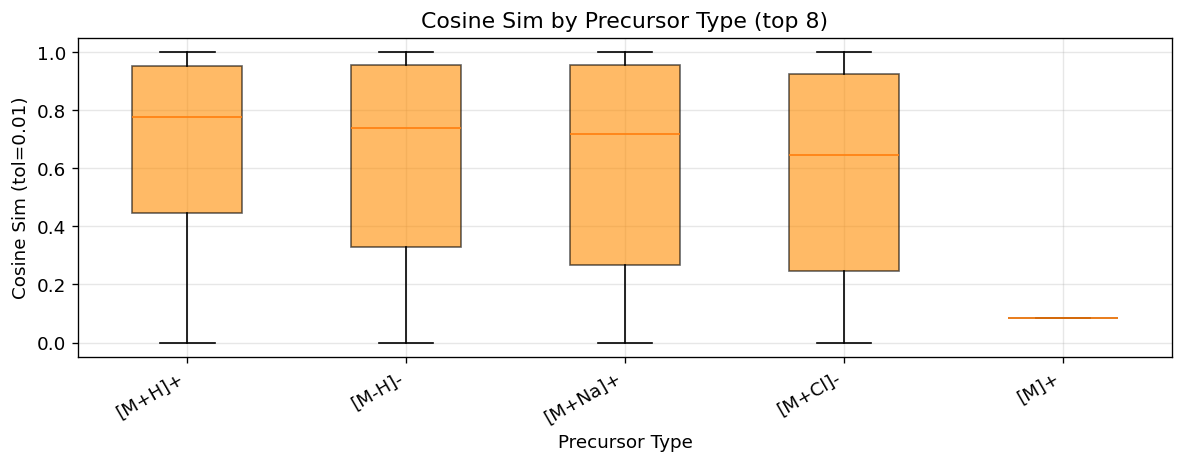

In [11]:
prec_order = df_top.groupby("prec_type")["cos_sim_0.01"].median().sort_values(ascending=False).index.tolist()
groups = [df_top.loc[df_top["prec_type"] == g, "cos_sim_0.01"].dropna().values for g in prec_order]

fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(groups, labels=prec_order, patch_artist=True, showfliers=False,
           boxprops=dict(facecolor="darkorange", alpha=0.6))
ax.set_title("Cosine Sim by Precursor Type (top 8)")
ax.set_xlabel("Precursor Type")
ax.set_ylabel("Cosine Sim (tol=0.01)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 6. Performance by Ion Mode

In [12]:
ion_stats = (
    df[df["ion_mode"].isin(["P", "N"])]
    .groupby("ion_mode")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
ion_stats

cos_sim_0.01                cos_hun               
                 mean  median  count    mean  median  count
ion_mode                                                   
N              0.6292  0.7313  22064  0.6608  0.7722  22064
P              0.6701  0.7704  63594  0.6892  0.7928  63594

## 7. Performance by Fragmentation Mode (HCD vs CID)

In [13]:
frag_stats = (
    df.groupby("frag_mode")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
frag_stats

cos_sim_0.01                cos_hun               
                  mean  median  count    mean  median  count
frag_mode                                                   
CID             0.5274  0.5420  11379  0.5273  0.5456  11379
HCD             0.6798  0.7851  74281  0.7056  0.8107  74281

## 8. Effect of Collision Energy on Performance

In [14]:
df_nce = df[(df["nce"].notna()) & (df["nce"] > 0) & (df["nce"] <= 200)].copy()
df_nce["nce_bin"] = pd.cut(df_nce["nce"], bins=[0, 20, 30, 40, 60, 80, 120, 200], right=True)

nce_stats = (
    df_nce.groupby("nce_bin", observed=True)[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
nce_stats

cos_sim_0.01                cos_hun               
                   mean  median  count    mean  median  count
nce_bin                                                      
(0, 20]          0.7933  0.9351  12419  0.8291  0.9451  12419
(20, 30]         0.7504  0.8915   7395  0.7850  0.9105   7395
(30, 40]         0.6230  0.7099  13986  0.6509  0.7479  13986
(40, 60]         0.6987  0.8148  13471  0.7259  0.8379  13471
(60, 80]         0.6457  0.7184   7647  0.6680  0.7478   7647
(80, 120]        0.6310  0.6862  12192  0.6468  0.7077  12192
(120, 200]       0.5994  0.6462   9482  0.6133  0.6631   9482

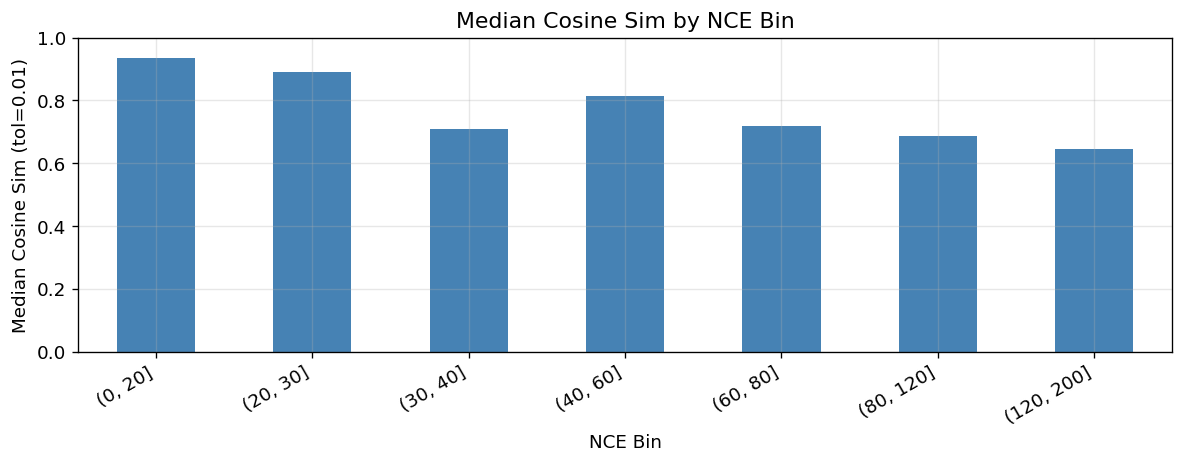

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
nce_med = df_nce.groupby("nce_bin", observed=True)["cos_sim_0.01"].median()
nce_med.plot(kind="bar", ax=ax, color="steelblue", edgecolor="none")
ax.set_title("Median Cosine Sim by NCE Bin")
ax.set_xlabel("NCE Bin")
ax.set_ylabel("Median Cosine Sim (tol=0.01)")
ax.set_ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 9. Performance by Dataset Source

In [16]:
dset_stats = (
    df.groupby("dset")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
dset_stats

cos_sim_0.01                cos_hun               
                   mean  median  count    mean  median  count
dset                                                         
mona23           0.5340  0.5586   7565  0.5448  0.5933   7565
nist23_hr1       0.6767  0.7819  44317  0.6980  0.8045  44317
nist23_hr2       0.6651  0.7634  33778  0.6914  0.7926  33778

## 10. Performance vs Molecular Properties

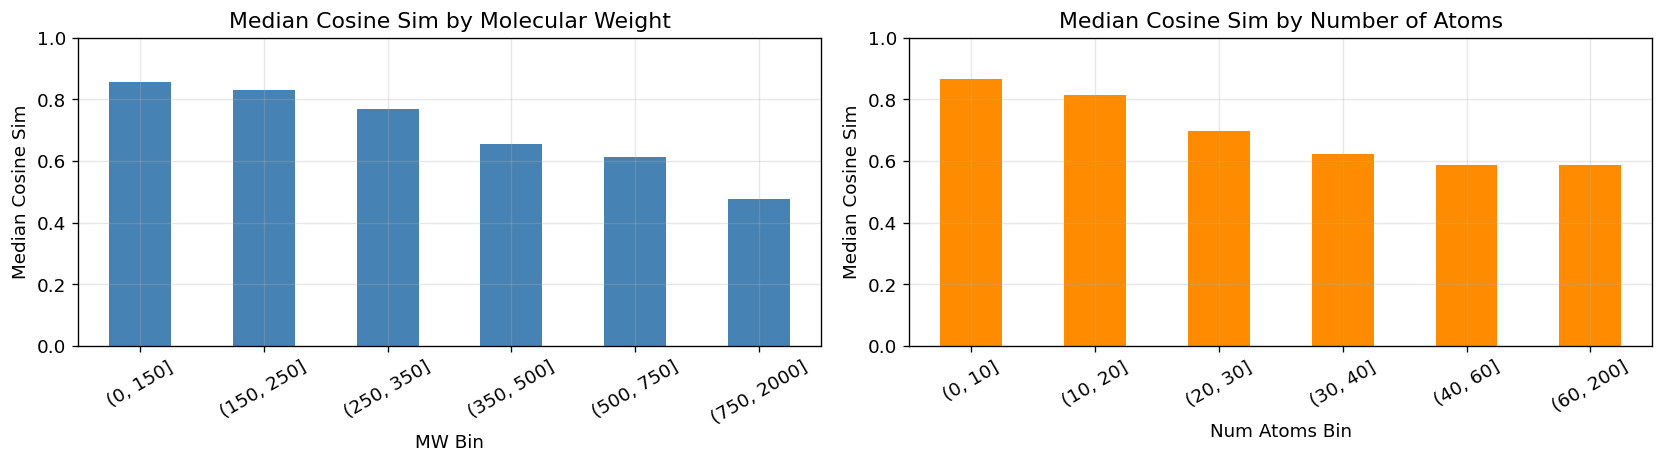

In [17]:
df_mol = df[(df["mw"].notna()) & (df["num_atoms"].notna())].copy()
df_mol["mw_bin"] = pd.cut(df_mol["mw"], bins=[0, 150, 250, 350, 500, 750, 2000], right=True)
df_mol["natoms_bin"] = pd.cut(df_mol["num_atoms"], bins=[0, 10, 20, 30, 40, 60, 200], right=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

mw_med = df_mol.groupby("mw_bin", observed=True)["cos_sim_0.01"].median()
mw_med.plot(kind="bar", ax=axes[0], color="steelblue", edgecolor="none")
axes[0].set_title("Median Cosine Sim by Molecular Weight")
axes[0].set_xlabel("MW Bin")
axes[0].set_ylabel("Median Cosine Sim")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=30)

na_med = df_mol.groupby("natoms_bin", observed=True)["cos_sim_0.01"].median()
na_med.plot(kind="bar", ax=axes[1], color="darkorange", edgecolor="none")
axes[1].set_title("Median Cosine Sim by Number of Atoms")
axes[1].set_xlabel("Num Atoms Bin")
axes[1].set_ylabel("Median Cosine Sim")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 11. Out-of-Spectrum Probability vs Similarity

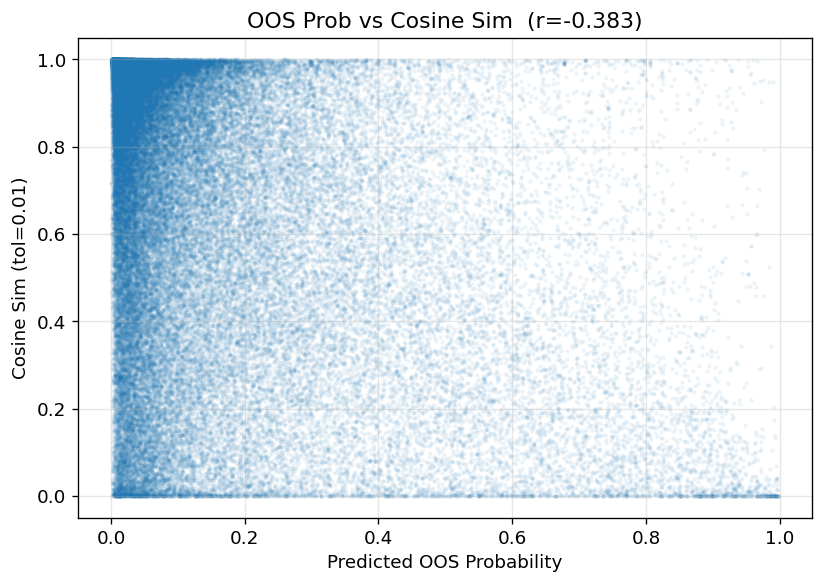

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    df["pred_oos_prob"],
    df["cos_sim_0.01"],
    alpha=0.05,
    s=3,
    rasterized=True,
)
corr = df[["pred_oos_prob", "cos_sim_0.01"]].corr().iloc[0, 1]
ax.set_xlabel("Predicted OOS Probability")
ax.set_ylabel("Cosine Sim (tol=0.01)")
ax.set_title(f"OOS Prob vs Cosine Sim  (r={corr:.3f})")
plt.tight_layout()
plt.show()

In [19]:
df["oos_bin"] = pd.cut(df["pred_oos_prob"], bins=[0, 0.05, 0.1, 0.2, 0.5, 1.0], right=True)
oos_stats = (
    df.groupby("oos_bin", observed=True)[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
oos_stats

cos_sim_0.01                cos_hun               
                    mean  median  count    mean  median  count
oos_bin                                                       
(0.0, 0.05]       0.7642  0.9000  35435  0.7927  0.9142  35435
(0.05, 0.1]       0.6843  0.7947  15620  0.7110  0.8182  15620
(0.1, 0.2]        0.6338  0.7094  13780  0.6557  0.7330  13780
(0.2, 0.5]        0.5415  0.5581  14327  0.5572  0.5811  14327
(0.5, 1.0]        0.3439  0.2612   6498  0.3380  0.2622   6498

## 12. Top / Bottom Predictions

In [20]:
display_cols = ["spec_id", "mol_id", "smiles", "formula", "prec_type", "inst_type", "cos_sim_0.01", "cos_hun"]

print("=== Top 10 predictions ===")
display(df.nlargest(10, "cos_sim_0.01")[display_cols].reset_index(drop=True))

print("=== Bottom 10 predictions ===")
display(df.nsmallest(10, "cos_sim_0.01")[display_cols].reset_index(drop=True))

=== Top 10 predictions ===


,spec_id,mol_id,smiles,formula,prec_type,inst_type,cos_sim_0.01,cos_hun
0,1829378,15901,CCCCCCCCCCCCCCCC(=O)O,C16H32O2,[M-H]-,QTOF,1.000000,1.000000
1,1893579,48819,O=S(=O)(O)C(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F)F,C5HF11O3S,[M-H]-,QTOF,1.000000,1.000000
2,1829033,15901,CCCCCCCCCCCCCCCC(=O)O,C16H32O2,[M-H]-,QTOF,1.000000,1.000000
3,1155016,45574,O=C(O)c1cc(Cl)ccc1C(F)(F)F,C8H4ClF3O2,[M-H]-,FT,1.000000,1.000000
4,1866217,52163,c1c[nH]nn1,C2H3N3,[M+H]+,FT,1.000000,1.000000
5,1866216,52163,c1c[nH]nn1,C2H3N3,[M+H]+,FT,1.000000,1.000000
6,1822416,11476,CC=C1CC2(CO)OC2(C)C(=O)OCC2=CC[N+]3([O-])CCC(O...,C18H23NO7,[M+H]+,FT,1.000000,0.999999
7,1866215,52163,c1c[nH]nn1,C2H3N3,[M+H]+,FT,0.999999,0.999999
8,1893626,48846,O=S(=O)(O)CCC(F)(F)C(F)(F)C(F)(F)C(F)(F)C(F)(F...,C10H5F17O3S,[M-H]-,QTOF,0.999999,0.999999
9,551714,27314,COc1ccc(-c2nc3cc([N+](=O)[O-])ccc3[nH]2)cc1,C14H11N3O3,[M-H]-,FT,0.999999,0.999999


=== Bottom 10 predictions ===


,spec_id,mol_id,smiles,formula,prec_type,inst_type,cos_sim_0.01,cos_hun
0,9358,19838,CCOc1cc(=O)oc2ccc(OC)cc12,C12H12O4,[M+H]+,FT,0.0,0.764567
1,9564,13772,CCCC(O)CC,C6H14O,[M+H]+,QTOF,0.0,0.000000
2,9671,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.057358
3,9672,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.028581
4,9673,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.012589
5,9674,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.006699
6,9675,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.002818
7,9676,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.004042
8,9677,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.000000
9,9678,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.001769


## 13. Performance by ClassyFire Superclass

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(14, 14))

# Superclass distribution (all)
super_counts = df["superklass"].value_counts()
axes[0].bar(range(len(super_counts)), super_counts.values, color="steelblue", alpha=0.8)
axes[0].set_xticks(range(len(super_counts)))
axes[0].set_xticklabels(super_counts.index, rotation=45, ha="right", fontsize=9)
axes[0].set_title("Spectrum Count by ClassyFire Superclass")
axes[0].set_ylabel("Count")
for i, v in enumerate(super_counts.values):
    axes[0].text(i, v + 20, f"{v:,}", ha="center", va="bottom", fontsize=7)

# Class distribution (top 25)
klass_counts = df["klass"].value_counts().head(25)
axes[1].bar(range(len(klass_counts)), klass_counts.values, color="darkorange", alpha=0.8)
axes[1].set_xticks(range(len(klass_counts)))
axes[1].set_xticklabels(klass_counts.index, rotation=55, ha="right", fontsize=8)
axes[1].set_title("Spectrum Count by ClassyFire Class (Top 25)")
axes[1].set_ylabel("Count")

# Subclass distribution (top 25)
sub_counts = df["subklass"].value_counts().head(25)
axes[2].bar(range(len(sub_counts)), sub_counts.values, color="mediumseagreen", alpha=0.8)
axes[2].set_xticks(range(len(sub_counts)))
axes[2].set_xticklabels(sub_counts.index, rotation=55, ha="right", fontsize=8)
axes[2].set_title("Spectrum Count by ClassyFire Subclass (Top 25)")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

print(f"Spectra with no superklass label: {df['superklass'].isna().sum():,}")
print(f"Spectra with no klass label:      {df['klass'].isna().sum():,}")
print(f"Spectra with no subklass label:   {df['subklass'].isna().sum():,}")

In [21]:
cf_super_stats = (
    df.dropna(subset=["superklass"])
    .groupby("superklass")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
cf_super_stats.sort_values(("cos_sim_0.01", "median"), ascending=False)

cos_sim_0.01                cos_hun  \
                                                  mean  median  count    mean   
superklass                                                                      
nucleosides, nucleotides, and analogues         0.7468  0.9252    662  0.7375   
organic nitrogen compounds                      0.7351  0.8434   1733  0.7435   
organophosphorus compounds                      0.6160  0.8142     76  0.6159   
benzenoids                                      0.6858  0.8021  23800  0.7093   
organohalogen compounds                         0.6211  0.8012    454  0.6499   
organosulfur compounds                          0.6298  0.7821    666  0.7201   
organic acids and derivatives                   0.6596  0.7658   9031  0.6748   
organoheterocyclic compounds                    0.6635  0.7614  28087  0.6854   
organic oxygen compounds                        0.6355  0.7325   3459  0.6613   
alkaloids and derivatives                       0.6303  0.7286   1162  0.6205   
phenylpropanoids and polyketides                0.6238  0.6965   7721  0.6552   
lipids and lipid-like molecules                 0.6094  0.6804   7799  0.6344   
organic polymers                                0.6116  0.6797    518  0.5936   
organic 1,3-dipolar compounds                   0.5724  0.5963    131  0.6112   
lignans, neolignans and related compounds       0.5042  0.5368    262  0.5602   
hydrocarbon derivatives                         0.4550  0.4281     85  0.4046   
organic salts                                   0.1892  0.0468     13  0.1892   
organometallic compounds                        0.0001  0.0001      1  0.0000   

                                                          
                                           median  count  
superklass                                                
nucleosides, nucleotides, and analogues    0.9196    662  
organic nitrogen compounds                 0.8512   1733  
organophosphorus compounds                 0.8142     76  
benzenoids                                 0.8231  23800  
organohalogen compounds                    0.8225    454  
organosulfur compounds                     0.8788    666  
organic acids and derivatives              0.7862   9031  
organoheterocyclic compounds               0.7880  28087  
organic oxygen compounds                   0.7649   3459  
alkaloids and derivatives                  0.7295   1162  
phenylpropanoids and polyketides           0.7452   7721  
lipids and lipid-like molecules            0.7116   7799  
organic polymers                           0.6941    518  
organic 1,3-dipolar compounds              0.6132    131  
lignans, neolignans and related compounds  0.6114    262  
hydrocarbon derivatives                    0.4030     85  
organic salts                              0.0468     13  
organometallic compounds                   0.0000      1

/tmp/ipykernel_402002/100713300.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=[f"{s}\n(n={c:,})" for s, c in zip(super_order, counts)],


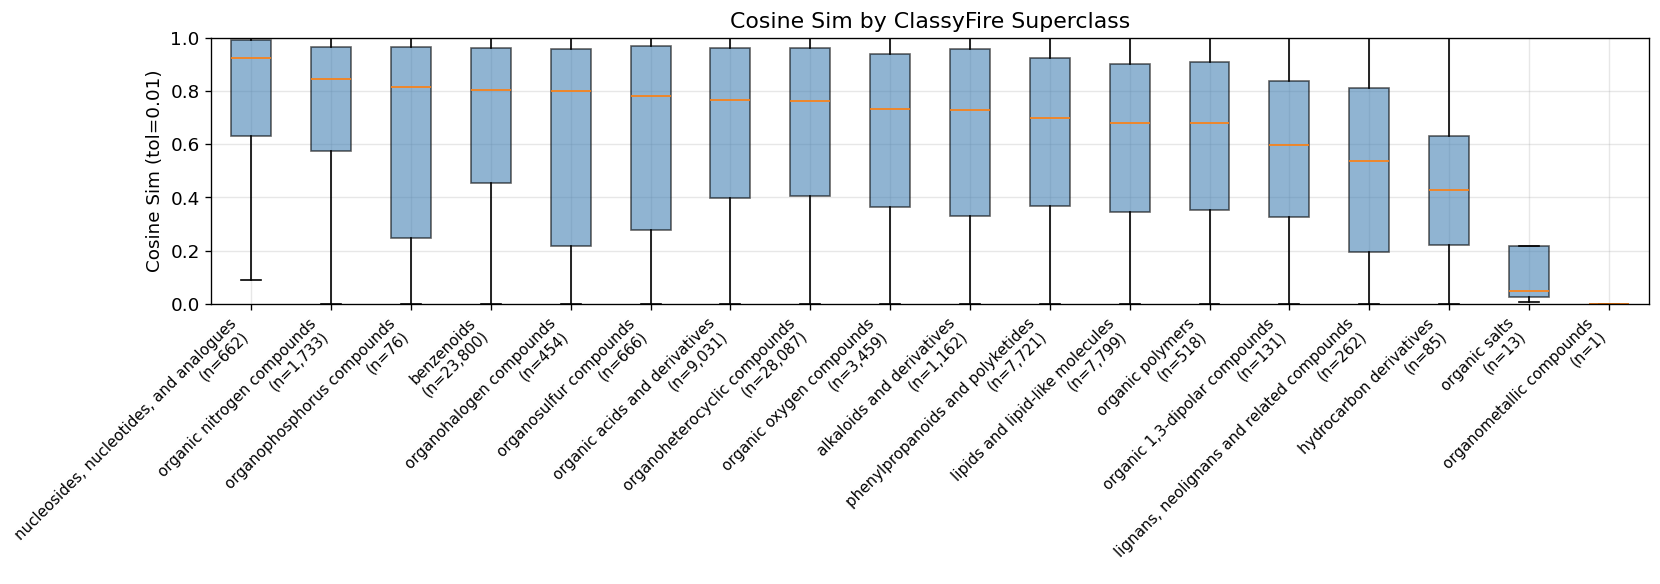

In [22]:
df_cf = df.dropna(subset=["superklass"])
super_order = df_cf.groupby("superklass")["cos_sim_0.01"].median().sort_values(ascending=False).index.tolist()
groups = [df_cf.loc[df_cf["superklass"] == g, "cos_sim_0.01"].values for g in super_order]
counts = [len(g) for g in groups]

fig, ax = plt.subplots(figsize=(14, 5))
ax.boxplot(groups, labels=[f"{s}\n(n={c:,})" for s, c in zip(super_order, counts)],
           patch_artist=True, showfliers=False,
           boxprops=dict(facecolor="steelblue", alpha=0.6))
ax.set_title("Cosine Sim by ClassyFire Superclass")
ax.set_ylabel("Cosine Sim (tol=0.01)")
ax.set_ylim(0, 1)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.tight_layout()
plt.show()

## 14. Performance by ClassyFire Class (Top 25)

In [23]:
top25_classes = df["klass"].value_counts().head(25).index.tolist()
df_klass = df[df["klass"].isin(top25_classes)].dropna(subset=["klass"])

cf_klass_stats = (
    df_klass.groupby("klass")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
cf_klass_stats.sort_values(("cos_sim_0.01", "median"), ascending=False)

cos_sim_0.01                cos_hun  \
                                            mean  median  count    mean   
klass                                                                     
piperidines                               0.7653  0.8893   1499  0.7710   
benzimidazoles                            0.7160  0.8524   1121  0.7379   
organonitrogen compounds                  0.7351  0.8434   1733  0.7435   
diazinanes                                0.7260  0.8316    906  0.7439   
benzene and substituted derivatives       0.7031  0.8206  18547  0.7251   
indoles and derivatives                   0.6936  0.8182   2586  0.7272   
imidazopyrimidines                        0.6921  0.8059    659  0.6987   
fatty acyls                               0.6838  0.7845   2207  0.6963   
pyridines and derivatives                 0.6674  0.7824   2744  0.6901   
naphthalenes                              0.6682  0.7819   1474  0.7108   
diazanaphthalenes                         0.6833  0.7751    782  0.6982   
carboxylic acids and derivatives          0.6655  0.7732   7376  0.6790   
diazines                                  0.6708  0.7627   1288  0.6981   
azoles                                    0.6633  0.7496   3658  0.6838   
phenols                                   0.6433  0.7472   1123  0.6649   
flavonoids                                0.6503  0.7441   2643  0.6931   
quinolines and derivatives                0.6543  0.7345   2182  0.6883   
organooxygen compounds                    0.6355  0.7325   3459  0.6613   
phenol ethers                             0.6523  0.7251   1454  0.6702   
coumarins and derivatives                 0.6192  0.6975    894  0.6441   
cinnamic acids and derivatives            0.6133  0.6963    772  0.6291   
prenol lipids                             0.5838  0.6343   3101  0.6087   
stilbenes                                 0.5895  0.6187    785  0.6092   
steroids and steroid derivatives          0.5632  0.5951   1793  0.6004   
benzopyrans                               0.5277  0.5113    985  0.5588   

                                                    
                                     median  count  
klass                                               
piperidines                          0.8931   1499  
benzimidazoles                       0.8700   1121  
organonitrogen compounds             0.8512   1733  
diazinanes                           0.8416    906  
benzene and substituted derivatives  0.8397  18547  
indoles and derivatives              0.8524   2586  
imidazopyrimidines                   0.8211    659  
fatty acyls                          0.8006   2207  
pyridines and derivatives            0.8070   2744  
naphthalenes                         0.8208   1474  
diazanaphthalenes                    0.7861    782  
carboxylic acids and derivatives     0.7915   7376  
diazines                             0.7932   1288  
azoles                               0.7751   3658  
phenols                              0.7666   1123  
flavonoids                           0.7882   2643  
quinolines and derivatives           0.7772   2182  
organooxygen compounds               0.7649   3459  
phenol ethers                        0.7456   1454  
coumarins and derivatives            0.7305    894  
cinnamic acids and derivatives       0.7448    772  
prenol lipids                        0.6681   3101  
stilbenes                            0.6616    785  
steroids and steroid derivatives     0.6476   1793  
benzopyrans                          0.5632    985

/tmp/ipykernel_402002/3139794100.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=[f"{k}\n(n={c:,})" for k, c in zip(klass_order, counts)],


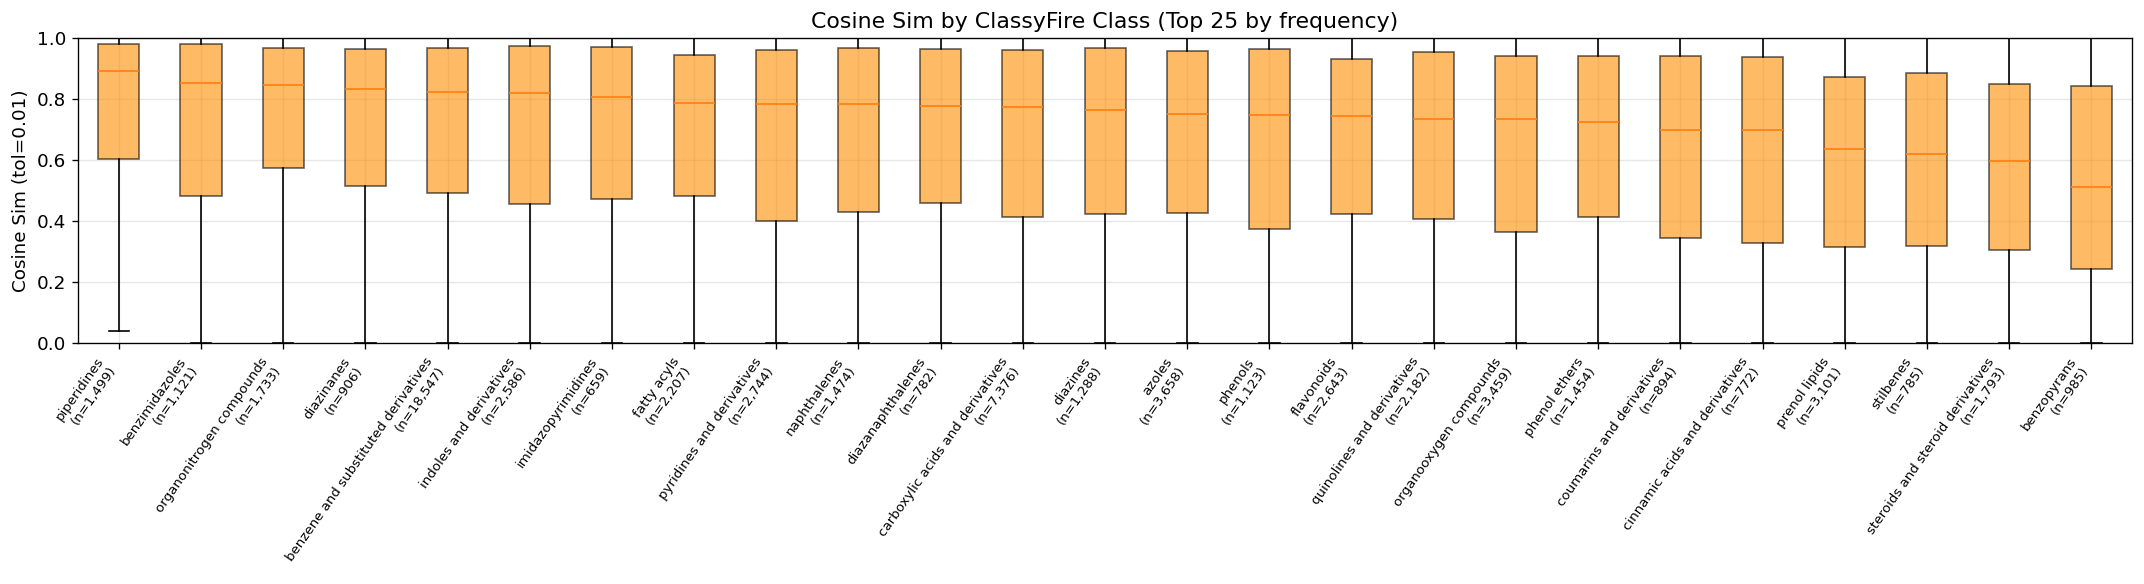

In [24]:
klass_order = df_klass.groupby("klass")["cos_sim_0.01"].median().sort_values(ascending=False).index.tolist()
groups = [df_klass.loc[df_klass["klass"] == g, "cos_sim_0.01"].values for g in klass_order]
counts = [len(g) for g in groups]

fig, ax = plt.subplots(figsize=(18, 5))
ax.boxplot(groups, labels=[f"{k}\n(n={c:,})" for k, c in zip(klass_order, counts)],
           patch_artist=True, showfliers=False,
           boxprops=dict(facecolor="darkorange", alpha=0.6))
ax.set_title("Cosine Sim by ClassyFire Class (Top 25 by frequency)")
ax.set_ylabel("Cosine Sim (tol=0.01)")
ax.set_ylim(0, 1)
plt.xticks(rotation=55, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

## 15. Performance by ClassyFire Subclass (Top 25)

In [25]:
top25_subklasses = df["subklass"].value_counts().head(25).index.tolist()
df_sub = df[df["subklass"].isin(top25_subklasses)].dropna(subset=["subklass"])

cf_sub_stats = (
    df_sub.groupby("subklass")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
cf_sub_stats.sort_values(("cos_sim_0.01", "median"), ascending=False)

cos_sim_0.01               cos_hun  \
                                                  mean  median count    mean   
subklass                                                                       
halobenzenes                                    0.7977  0.9184  1390  0.8024   
benzimidazoles                                  0.7251  0.8668  1042  0.7485   
anilides                                        0.7378  0.8501  2367  0.7567   
amines                                          0.7307  0.8446   955  0.7510   
piperazines                                     0.7220  0.8304   867  0.7405   
benzoic acids and derivatives                   0.7136  0.8253  4506  0.7387   
pyridinecarboxylic acids and derivatives        0.6757  0.8178   840  0.7066   
indoles                                         0.6804  0.8171  1227  0.7199   
carbonyl compounds                              0.6959  0.8139  1776  0.7077   
fatty acids and conjugates                      0.6983  0.8135  1281  0.7081   
amino acids, peptides, and analogues            0.6822  0.7973  6135  0.6964   
flavonoid glycosides                            0.6762  0.7971  1037  0.7559   
benzodiazines                                   0.6922  0.7841   735  0.7080   
pyrimidines and pyrimidine derivatives          0.6753  0.7745  1011  0.7078   
halopyridines                                   0.6510  0.7528  1221  0.6759   
imidazoles                                      0.6569  0.7458   672  0.6743   
phenol ethers                                   0.6665  0.7416   954  0.6866   
benzenesulfonamides                             0.6346  0.7318  1301  0.6709   
o-methylated flavonoids                         0.6366  0.6775   765  0.6557   
nitrobenzenes                                   0.6049  0.6735   821  0.6155   
pyrazoles                                       0.6356  0.6628  1115  0.6578   
carbohydrates and carbohydrate conjugates       0.5751  0.6263   818  0.6083   
stilbenes                                       0.5895  0.6187   785  0.6092   
ethers                                          0.5468  0.5691   647  0.5949   
1-benzopyrans                                   0.5264  0.5049   812  0.5626   

                                                         
                                           median count  
subklass                                                 
halobenzenes                               0.9175  1390  
benzimidazoles                             0.8840  1042  
anilides                                   0.8624  2367  
amines                                     0.8626   955  
piperazines                                0.8391   867  
benzoic acids and derivatives              0.8496  4506  
pyridinecarboxylic acids and derivatives   0.8475   840  
indoles                                    0.8577  1227  
carbonyl compounds                         0.8249  1776  
fatty acids and conjugates                 0.8260  1281  
amino acids, peptides, and analogues       0.8137  6135  
flavonoid glycosides                       0.8667  1037  
benzodiazines                              0.7968   735  
pyrimidines and pyrimidine derivatives     0.8157  1011  
halopyridines                              0.7733  1221  
imidazoles                                 0.7685   672  
phenol ethers                              0.7700   954  
benzenesulfonamides                        0.7703  1301  
o-methylated flavonoids                    0.7109   765  
nitrobenzenes                              0.6836   821  
pyrazoles                                  0.6985  1115  
carbohydrates and carbohydrate conjugates  0.6775   818  
stilbenes                                  0.6616   785  
ethers                                     0.6613   647  
1-benzopyrans                              0.5675   812

/tmp/ipykernel_402002/2366441236.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(groups, labels=[f"{s}\n(n={c:,})" for s, c in zip(sub_order, counts)],


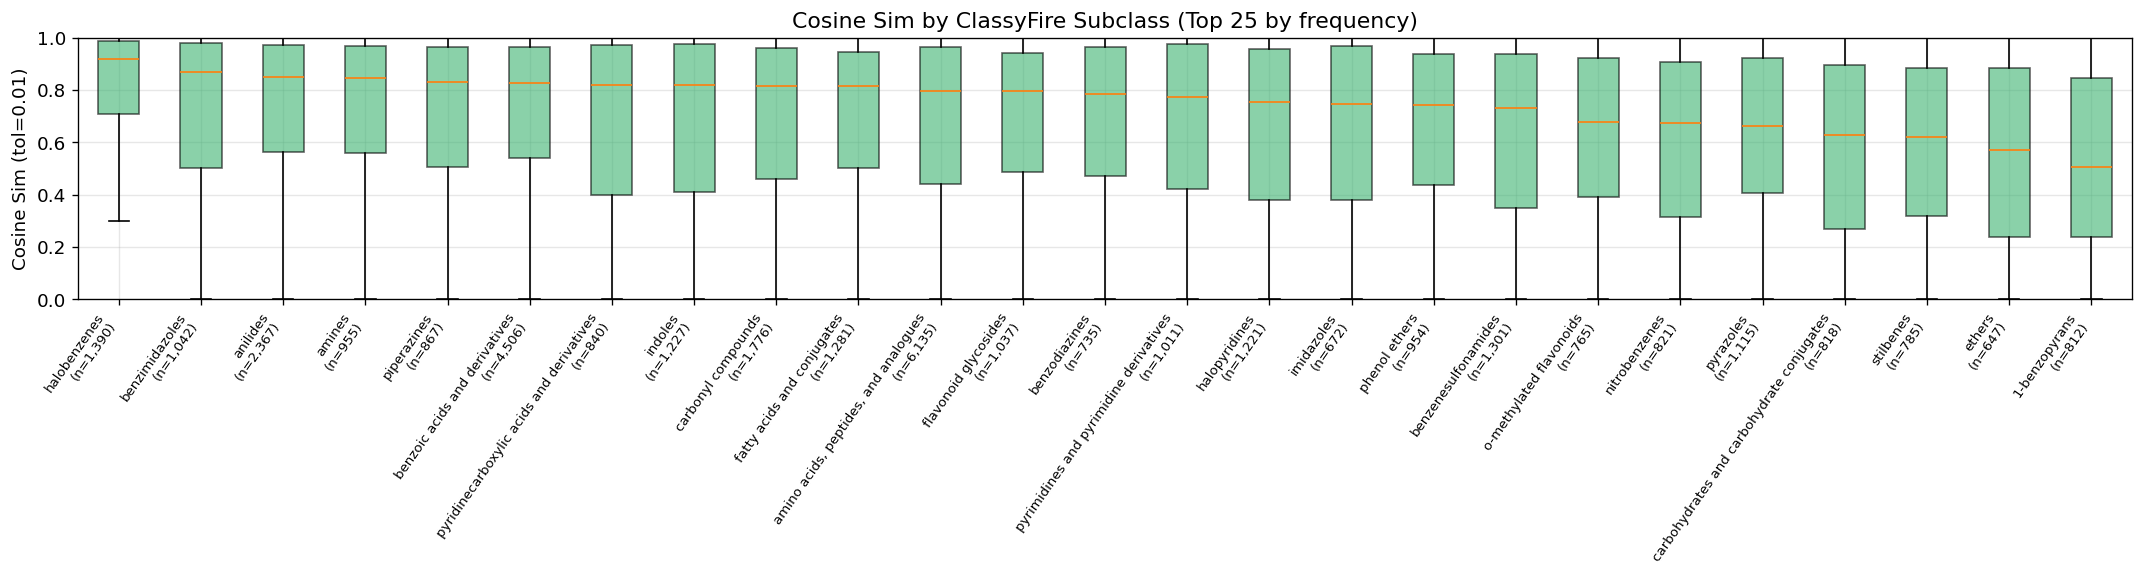

In [26]:
sub_order = df_sub.groupby("subklass")["cos_sim_0.01"].median().sort_values(ascending=False).index.tolist()
groups = [df_sub.loc[df_sub["subklass"] == g, "cos_sim_0.01"].values for g in sub_order]
counts = [len(g) for g in groups]

fig, ax = plt.subplots(figsize=(18, 5))
ax.boxplot(groups, labels=[f"{s}\n(n={c:,})" for s, c in zip(sub_order, counts)],
           patch_artist=True, showfliers=False,
           boxprops=dict(facecolor="mediumseagreen", alpha=0.6))
ax.set_title("Cosine Sim by ClassyFire Subclass (Top 25 by frequency)")
ax.set_ylabel("Cosine Sim (tol=0.01)")
ax.set_ylim(0, 1)
plt.xticks(rotation=55, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

## 16. Summary Table

In [27]:
thresholds = [0.2, 0.5, 0.7, 0.9]

summary = {}
for t in thresholds:
    summary[f"cos_sim >= {t}"] = (df["cos_sim_0.01"] >= t).mean()

summary["mean cos_sim"] = df["cos_sim_0.01"].mean()
summary["median cos_sim"] = df["cos_sim_0.01"].median()
summary["mean cos_hun"] = df["cos_hun"].mean()
summary["median cos_hun"] = df["cos_hun"].median()
summary["n_spectra"] = len(df)
summary["n_molecules"] = df["mol_id"].nunique()

pd.Series(summary).round(4).to_frame("value")

,value
cos_sim >= 0.2,0.8654
cos_sim >= 0.5,0.6913
cos_sim >= 0.7,0.5522
cos_sim >= 0.9,0.3469
mean cos_sim,0.6595
median cos_sim,0.7620
mean cos_hun,0.6819
median cos_hun,0.7881
n_spectra,85660.0000
n_molecules,4560.0000
